# Ticket classification evaluation

Three saved runs, each using the same 100 reference tickets.

In [1]:
import hashlib
import os
import sys
from pathlib import Path
from typing import get_args

import matplotlib.pyplot as plt
import pandas as pd
from dotenv import load_dotenv
from IPython.display import display
from sklearn.metrics import confusion_matrix


RUN_ANALYSIS = False
N_RUNS = 3
CONCURRENCY = 3
BASE_URL = "http://127.0.0.1:8001"
EXPERIMENT_NOTE = (
    "Revised 100-ticket dataset; three fresh MCP runs; no automatic retries"
)

ROOT = Path.cwd()
while not (ROOT / "backend/app").is_dir():
    if ROOT == ROOT.parent:
        raise FileNotFoundError("Run this notebook from the project folder.")
    ROOT = ROOT.parent

sys.path.insert(0, str(ROOT / "backend"))
from app.schemas.types import (  # noqa: E402
    TicketCategory,
    TicketPriority,
    TicketSentiment,
)
from app.validation.evaluation_reporting import (  # noqa: E402
    estimate_costs,
    plot_matrix,
    report_run,
)
from app.validation.evaluation_runner import (  # noqa: E402
    backend_version,
    read_json,
    run_experiment,
)


DATA_FILE = ROOT / "backend/app/validation/scoring_tickets_100_draft.json"
EXPERIMENT_DIR = DATA_FILE.parent / "evaluation_results"
load_dotenv(ROOT / "backend/app/.env", override=False)
MODEL = os.getenv("OPENAI_MODEL", "gpt-6-luna").strip()
LABELS = {
    "category": list(get_args(TicketCategory)),
    "sentiment": list(get_args(TicketSentiment)),
    "priority": list(get_args(TicketPriority)),
}

## 1. Reference data

The `expected` labels are used only for scoring. They are never sent to the API.


In [2]:
tickets = read_json(DATA_FILE)
assert len(tickets) == 100
assert len({ticket["id"] for ticket in tickets}) == 100
assert N_RUNS == 3 and 1 <= CONCURRENCY <= 3
for ticket in tickets:
    for field, labels in LABELS.items():
        assert ticket["expected"][field] in labels

settings = {
    "dataset_hash": hashlib.sha256(DATA_FILE.read_bytes()).hexdigest(),
    **backend_version(ROOT),
    "model": MODEL,
    "experiment_note": EXPERIMENT_NOTE,
    "labels": LABELS,
    "base_url": BASE_URL,
    "concurrency": CONCURRENCY,
    "n_runs": N_RUNS,
}

class_counts = []
for field, labels in LABELS.items():
    for label in labels:
        count = sum(ticket["expected"][field] == label for ticket in tickets)
        class_counts.append({"task": field, "label": label, "count": count})
class_counts = pd.DataFrame(class_counts)
display(class_counts)

,task,label,count
0,category,General,12
1,category,Access,16
2,category,Billing,16
3,category,API,16
4,category,Bug,16
5,category,Feature Request,12
6,category,Performance,12
7,sentiment,Negative,28
8,sentiment,Neutral,54
9,sentiment,Positive,18


## 2. Optional API collection

Leave this disabled for the saved results. For a new experiment, choose a new `EXPERIMENT_DIR`, start the backend with `DEBUG=True`, and check the model and note before enabling it.
The helper saves each attempt and does not retry failed or interrupted requests.


In [3]:
run_dirs = [EXPERIMENT_DIR / f"run_{i:02d}" for i in range(1, N_RUNS + 1)]
if RUN_ANALYSIS:
    run_experiment(run_dirs, tickets, settings)
else:
    print("Using saved responses. No API calls.")

run_01: SCORE-003 - success (15.77s)
run_01: SCORE-002 - success (16.72s)
run_01: SCORE-001 - success (23.99s)
run_01: SCORE-004 - success (15.30s)
run_01: SCORE-005 - success (17.15s)
run_01: SCORE-006 - success (14.38s)
run_01: SCORE-007 - success (15.85s)
run_01: SCORE-008 - success (14.46s)
run_01: SCORE-009 - success (16.13s)
run_01: SCORE-011 - success (11.44s)
run_01: SCORE-010 - success (17.06s)
run_01: SCORE-012 - success (19.81s)
run_01: SCORE-013 - success (15.91s)
run_01: SCORE-014 - success (18.93s)
run_01: SCORE-015 - success (13.98s)
run_01: SCORE-016 - success (16.08s)
run_01: SCORE-017 - success (11.48s)
run_01: SCORE-018 - success (13.96s)
run_01: SCORE-020 - success (11.66s)
run_01: SCORE-019 - success (15.76s)
run_01: SCORE-021 - success (15.53s)
run_01: SCORE-022 - success (16.10s)
run_01: SCORE-023 - success (18.55s)
run_01: SCORE-024 - success (16.53s)
run_01: SCORE-025 - success (12.73s)
run_01: SCORE-026 - success (14.61s)
run_01: SCORE-027 - success (19.01s)
r

## 3. Saved reports

Generate predictions, scores, confusion matrices, timings and token reports.



 run_01

 run_02

 run_03


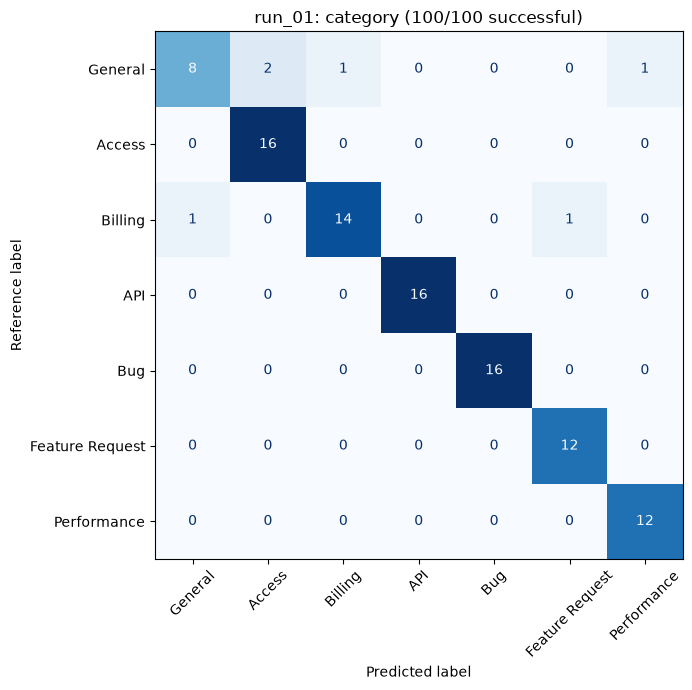

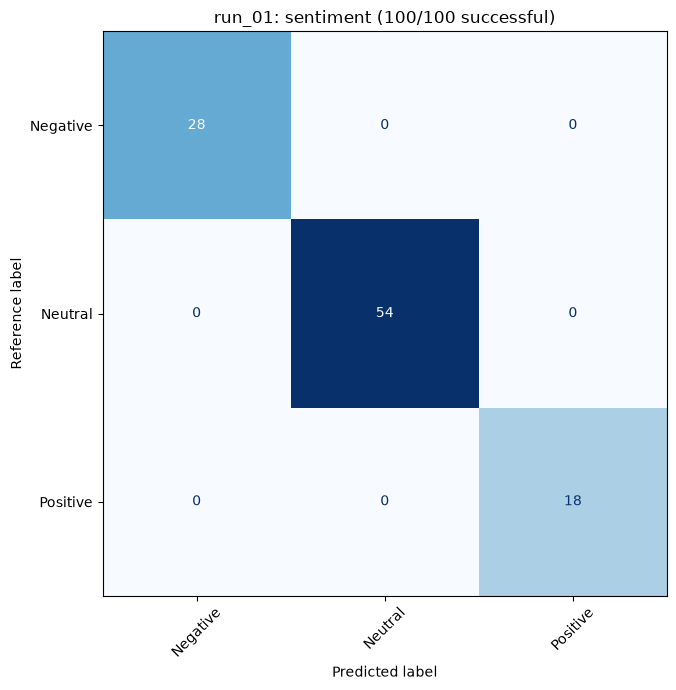

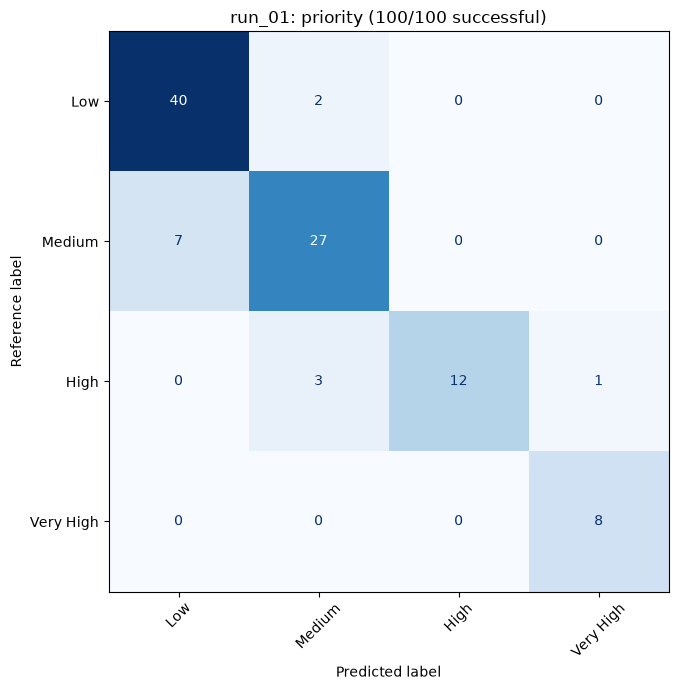

,run,task,total,successful,coverage,accuracy,macro_precision,macro_recall,macro_f1,correct_over_total
0,run_01,category,100,100,1.0,0.94,0.9368,0.9345,0.9323,0.94
1,run_01,sentiment,100,100,1.0,1.00,1.0000,1.0000,1.0000,1.00
2,run_01,priority,100,100,1.0,0.87,0.8959,0.8741,0.8788,0.87


,run,successful,failed,missing_or_interrupted,run_wall_seconds,wall_time_complete,timed_tickets,latency_mean_seconds,latency_std_seconds,latency_median_seconds,latency_p95_seconds,usage_available_tickets,usage_missing_tickets,observed_input_tokens,mean_input_tokens_where_available,observed_output_tokens,mean_output_tokens_where_available,observed_total_tokens,mean_total_tokens_where_available
0,run_01,100,0,0,545.181,True,100,16.278,3.287,15.764,24.009,100,0,906126,9061.26,106107,1061.07,1012233,10122.33


,id,backend_ticket_id,status,analysis_seconds,input_tokens,output_tokens,total_tokens
0,SCORE-001,MCP-F51965A5,success,23.986641,12743,1609,14352
1,SCORE-002,MCP-3230FB2E,success,16.719059,9121,1191,10312
2,SCORE-003,MCP-29E95FDF,success,15.767621,8846,885,9731
3,SCORE-004,MCP-0ACF2CC5,success,15.295227,9011,998,10009
4,SCORE-005,MCP-37C6C574,success,17.146324,9474,1559,11033
5,SCORE-006,MCP-0F394136,success,14.380524,9037,1117,10154
6,SCORE-007,MCP-805B6DAF,success,15.846789,8914,927,9841
7,SCORE-008,MCP-CD14DF66,success,14.464369,8874,964,9838
8,SCORE-009,MCP-6548D510,success,16.131515,9002,1097,10099
9,SCORE-010,MCP-7CC298D3,success,17.062332,9002,1031,10033


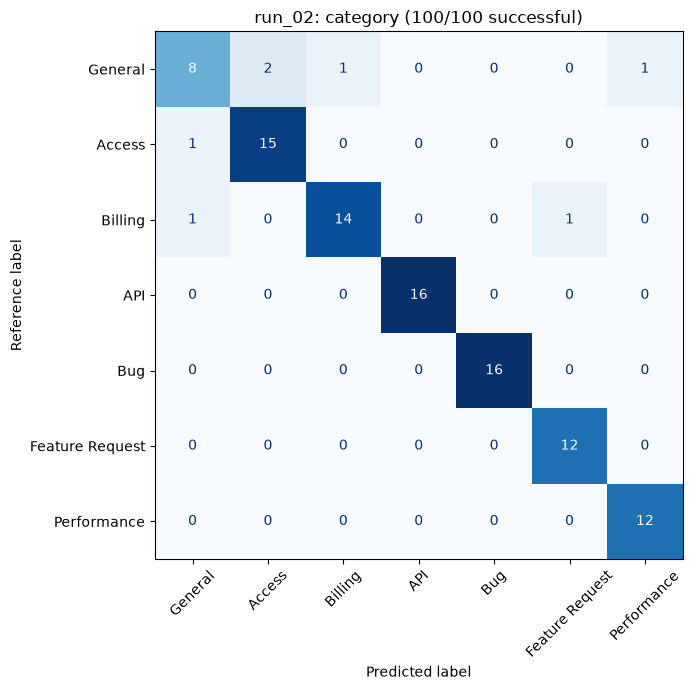

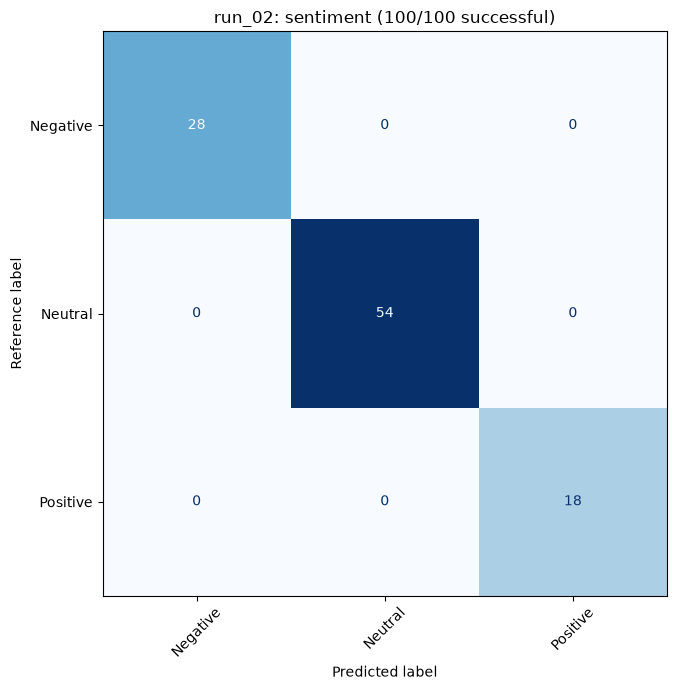

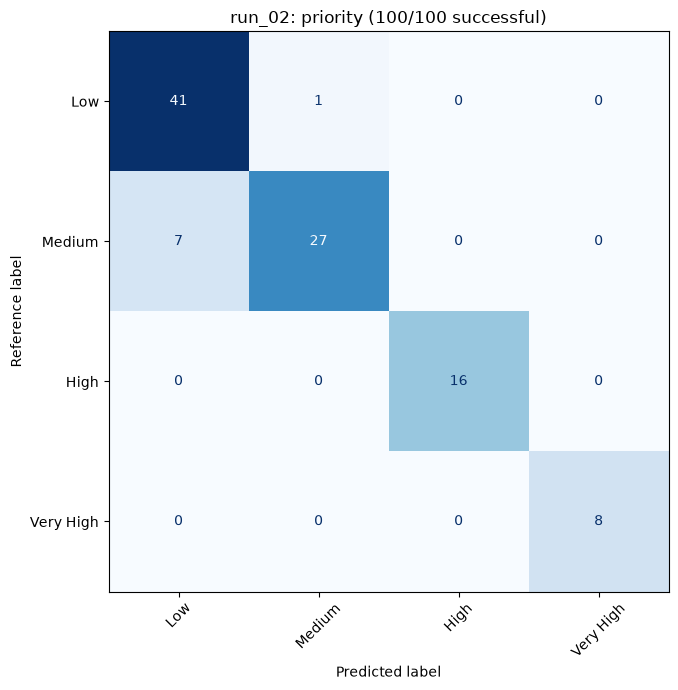

,run,task,total,successful,coverage,accuracy,macro_precision,macro_recall,macro_f1,correct_over_total
0,run_02,category,100,100,1.0,0.93,0.9231,0.9256,0.9228,0.93
1,run_02,sentiment,100,100,1.0,1.00,1.0000,1.0000,1.0000,1.00
2,run_02,priority,100,100,1.0,0.92,0.9546,0.9426,0.9455,0.92


,run,successful,failed,missing_or_interrupted,run_wall_seconds,wall_time_complete,timed_tickets,latency_mean_seconds,latency_std_seconds,latency_median_seconds,latency_p95_seconds,usage_available_tickets,usage_missing_tickets,observed_input_tokens,mean_input_tokens_where_available,observed_output_tokens,mean_output_tokens_where_available,observed_total_tokens,mean_total_tokens_where_available
0,run_02,100,0,0,561.643,True,100,16.635,4.184,15.542,24.087,100,0,904563,9045.63,105322,1053.22,1009885,10098.85


,id,backend_ticket_id,status,analysis_seconds,input_tokens,output_tokens,total_tokens
0,SCORE-001,MCP-374A4530,success,36.928370,9016,1165,10181
1,SCORE-002,MCP-99DE0FFD,success,17.375106,9164,1253,10417
2,SCORE-003,MCP-99C3AFCE,success,15.172570,8918,957,9875
3,SCORE-004,MCP-0562F7B9,success,13.478848,8814,822,9636
4,SCORE-005,MCP-1DF805AD,success,18.480381,9185,1307,10492
5,SCORE-006,MCP-782F5F16,success,14.247924,8797,924,9721
6,SCORE-007,MCP-718FFBD1,success,23.696690,8800,894,9694
7,SCORE-008,MCP-B5583AE4,success,12.465492,8886,936,9822
8,SCORE-009,MCP-A8FE4624,success,27.096755,9037,1139,10176
9,SCORE-010,MCP-F21CD6BC,success,14.491130,9087,1155,10242


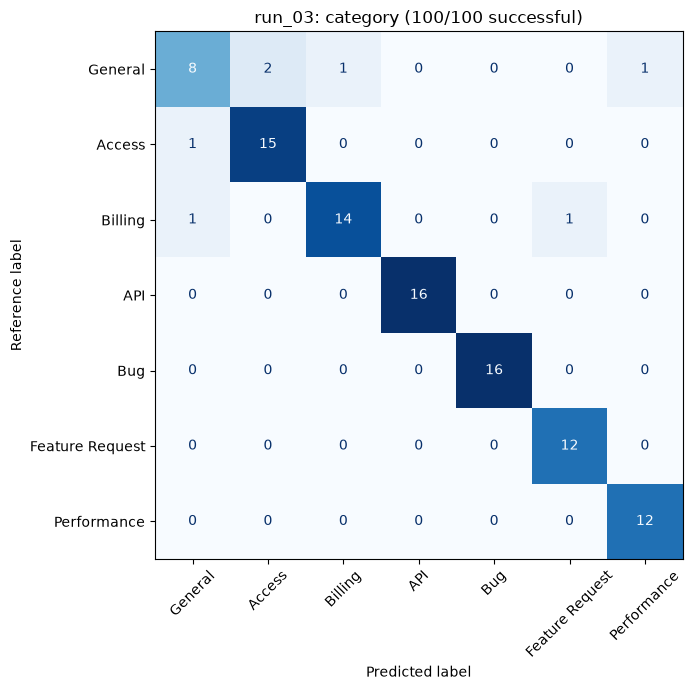

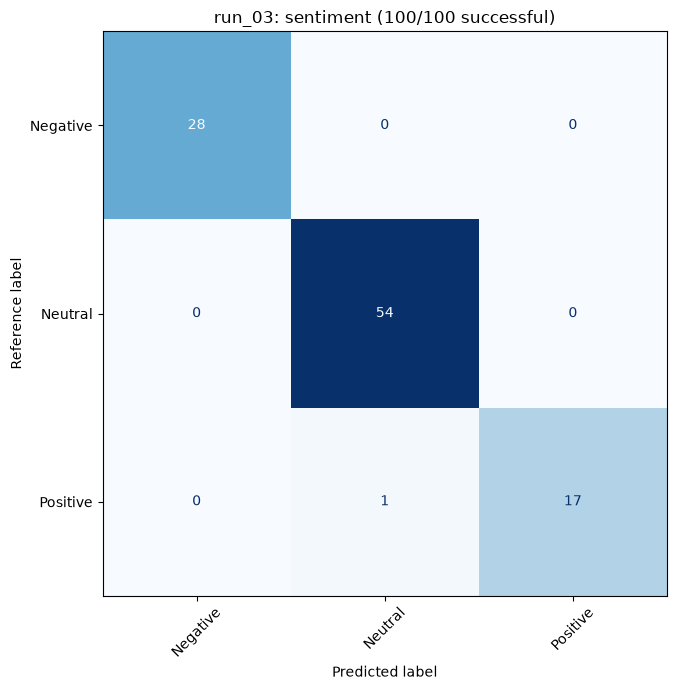

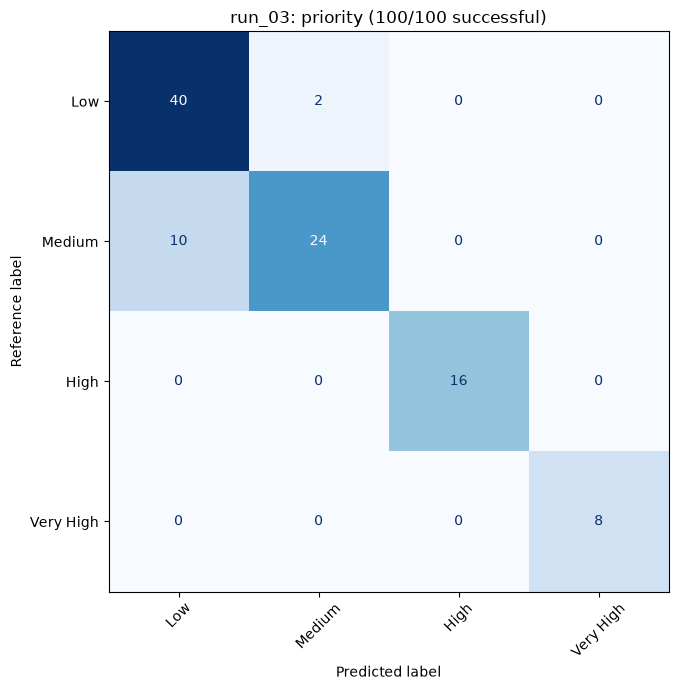

,run,task,total,successful,coverage,accuracy,macro_precision,macro_recall,macro_f1,correct_over_total
0,run_03,category,100,100,1.0,0.93,0.9231,0.9256,0.9228,0.93
1,run_03,sentiment,100,100,1.0,0.99,0.9939,0.9815,0.9874,0.99
2,run_03,priority,100,100,1.0,0.88,0.9308,0.9146,0.9174,0.88


,run,successful,failed,missing_or_interrupted,run_wall_seconds,wall_time_complete,timed_tickets,latency_mean_seconds,latency_std_seconds,latency_median_seconds,latency_p95_seconds,usage_available_tickets,usage_missing_tickets,observed_input_tokens,mean_input_tokens_where_available,observed_output_tokens,mean_output_tokens_where_available,observed_total_tokens,mean_total_tokens_where_available
0,run_03,100,0,0,675.986,True,100,19.937,7.902,17.069,35.832,100,0,899367,8993.67,103553,1035.53,1002920,10029.2


,id,backend_ticket_id,status,analysis_seconds,input_tokens,output_tokens,total_tokens
0,SCORE-001,MCP-781DCE4E,success,18.568278,9042,1088,10130
1,SCORE-002,MCP-75000020,success,21.865641,9087,1215,10302
2,SCORE-003,MCP-ED31C911,success,13.912180,8827,902,9729
3,SCORE-004,MCP-2AD76122,success,24.297111,8937,1074,10011
4,SCORE-005,MCP-917FF18E,success,18.846653,9101,1239,10340
5,SCORE-006,MCP-E3E3B6EE,success,17.764564,8878,893,9771
6,SCORE-007,MCP-C75DE553,success,16.696265,8991,1120,10111
7,SCORE-008,MCP-9F663530,success,24.698021,9288,1398,10686
8,SCORE-009,MCP-A87CC348,success,15.196047,9046,1188,10234
9,SCORE-010,MCP-9386CC63,success,15.063752,8865,946,9811


In [4]:
all_predictions, all_metrics, runtime_rows, loaded_settings = [], [], [], []
for run_dir in run_dirs:
    result_path = run_dir / "results.json"
    if not result_path.exists():
        print(run_dir.name, "- no saved results")
        continue
    saved = read_json(result_path)
    assert saved["settings"]["dataset_hash"] == settings["dataset_hash"], (
        "Reference dataset differs."
    )
    assert saved["settings"]["labels"] == LABELS, "Label definitions differ."
    loaded_settings.append(saved["settings"])
    assert all(s == loaded_settings[0] for s in loaded_settings), (
        "Runs have different experiment settings."
    )
    print("\n", run_dir.name)
    predictions, metrics, stats = report_run(
        saved,
        run_dir,
        tickets,
        LABELS,
        class_counts,
        include_previous_attempts=False,
    )
    all_predictions.append(predictions)
    all_metrics.append(metrics)
    runtime_rows.append(stats)

## 4. Compare runs

Mean and sample SD are calculated from complete runs. These summaries describe the retained successful subset; SD is not a confidence interval.


In [5]:
if all_metrics:
    summary_dir = EXPERIMENT_DIR / "comparison"
    summary_dir.mkdir(parents=True, exist_ok=True)
    comparison = pd.concat(all_metrics, ignore_index=True)
    details = pd.concat(all_predictions, ignore_index=True)
    runtime = pd.DataFrame(runtime_rows)
    complete_runs = comparison.groupby("run").coverage.min()
    complete_runs = complete_runs[complete_runs == 1].index.tolist()
    complete = comparison[comparison.run.isin(complete_runs)]
    metric_columns = [
        "accuracy",
        "macro_precision",
        "macro_recall",
        "macro_f1",
        "correct_over_total",
    ]
    average = complete.groupby("task")[metric_columns].agg(
        ["count", "mean", "std"]
    )
    average.columns = [f"{metric}_{stat}" for metric, stat in average.columns]
    display(comparison.round(4))
    display(average.round(4))
    print(
        f"Complete runs: {len(complete_runs)}/{N_RUNS}. "
        "SD is sample SD across runs, not a confidence interval."
    )
    comparison.to_csv(summary_dir / "metrics_by_run.csv", index=False)
    average.to_csv(summary_dir / "metrics_mean_std.csv")
    details.to_csv(summary_dir / "all_ticket_results.csv", index=False)
    runtime.to_csv(summary_dir / "runtime_tokens_by_run.csv", index=False)
    display(runtime.round(3))
    runtime_complete = runtime[runtime.run.isin(complete_runs)]
    numeric_columns = runtime_complete.select_dtypes(include="number").columns
    runtime_average = (
        runtime_complete[numeric_columns].agg(["count", "mean", "std"]).T
    )
    runtime_average.to_csv(summary_dir / "runtime_tokens_mean_std.csv")
    display(runtime_average.round(3))

else:
    print("No saved runs found.")

Complete runs: 3/3. SD is sample SD across runs, not a confidence interval.


,run,task,total,successful,coverage,accuracy,macro_precision,macro_recall,macro_f1,correct_over_total
0,run_01,category,100,100,1.0,0.94,0.9368,0.9345,0.9323,0.94
1,run_01,sentiment,100,100,1.0,1.00,1.0000,1.0000,1.0000,1.00
2,run_01,priority,100,100,1.0,0.87,0.8959,0.8741,0.8788,0.87
3,run_02,category,100,100,1.0,0.93,0.9231,0.9256,0.9228,0.93
4,run_02,sentiment,100,100,1.0,1.00,1.0000,1.0000,1.0000,1.00
5,run_02,priority,100,100,1.0,0.92,0.9546,0.9426,0.9455,0.92
6,run_03,category,100,100,1.0,0.93,0.9231,0.9256,0.9228,0.93
7,run_03,sentiment,100,100,1.0,0.99,0.9939,0.9815,0.9874,0.99
8,run_03,priority,100,100,1.0,0.88,0.9308,0.9146,0.9174,0.88


,accuracy_count,accuracy_mean,accuracy_std,macro_precision_count,macro_precision_mean,macro_precision_std,macro_recall_count,macro_recall_mean,macro_recall_std,macro_f1_count,macro_f1_mean,macro_f1_std,correct_over_total_count,correct_over_total_mean,correct_over_total_std
task,,,,,,,,,,,,,,,
category,3,0.9333,0.0058,3,0.9277,0.0079,3,0.9286,0.0052,3,0.9260,0.0055,3,0.9333,0.0058
priority,3,0.8900,0.0265,3,0.9271,0.0295,3,0.9104,0.0344,3,0.9139,0.0335,3,0.8900,0.0265
sentiment,3,0.9967,0.0058,3,0.9980,0.0035,3,0.9938,0.0107,3,0.9958,0.0073,3,0.9967,0.0058


,run,successful,failed,missing_or_interrupted,run_wall_seconds,wall_time_complete,timed_tickets,latency_mean_seconds,latency_std_seconds,latency_median_seconds,latency_p95_seconds,usage_available_tickets,usage_missing_tickets,observed_input_tokens,mean_input_tokens_where_available,observed_output_tokens,mean_output_tokens_where_available,observed_total_tokens,mean_total_tokens_where_available
0,run_01,100,0,0,545.181,True,100,16.278,3.287,15.764,24.009,100,0,906126,9061.26,106107,1061.07,1012233,10122.33
1,run_02,100,0,0,561.643,True,100,16.635,4.184,15.542,24.087,100,0,904563,9045.63,105322,1053.22,1009885,10098.85
2,run_03,100,0,0,675.986,True,100,19.937,7.902,17.069,35.832,100,0,899367,8993.67,103553,1035.53,1002920,10029.20


,count,mean,std
successful,3.0,100.000,0.000
failed,3.0,0.000,0.000
missing_or_interrupted,3.0,0.000,0.000
run_wall_seconds,3.0,594.270,71.245
timed_tickets,3.0,100.000,0.000
latency_mean_seconds,3.0,17.617,2.017
latency_std_seconds,3.0,5.124,2.447
latency_median_seconds,3.0,16.125,0.825
latency_p95_seconds,3.0,27.976,6.804
usage_available_tickets,3.0,100.000,0.000


## 5. Pooled matrices and agreement

The pooled matrices contain 300 decisions on the same 100 tickets. Pooled macro-F1 differs from mean run-level F1. Agreement measures consistency, not correctness.


Reports saved to: C:\Users\lenovo\Documents\thesis\backend\app\validation\evaluation_results


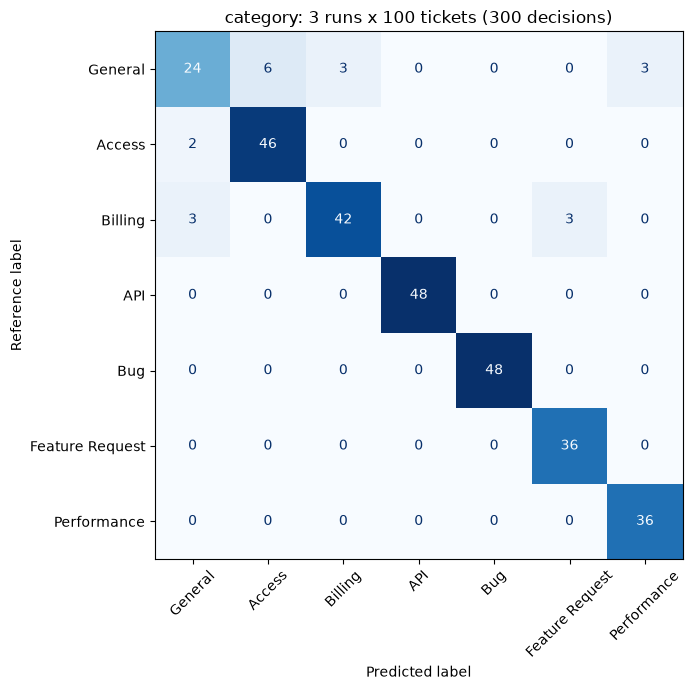

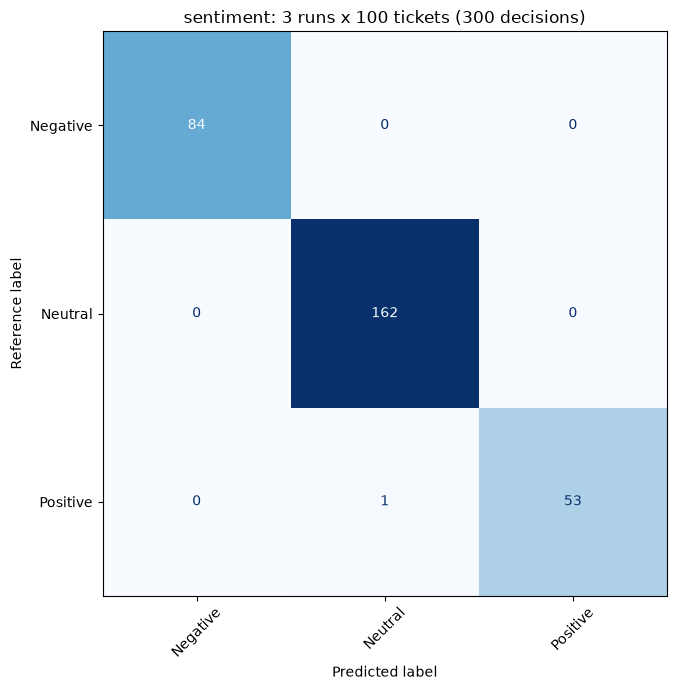

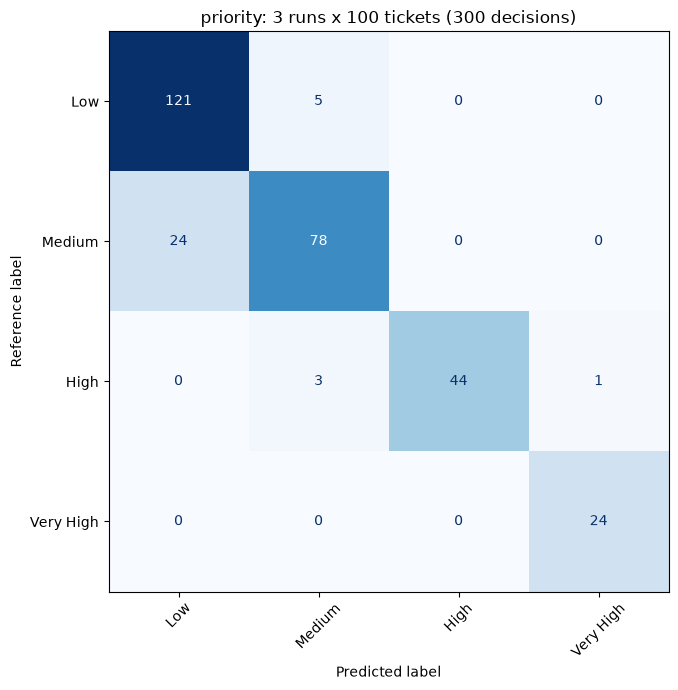

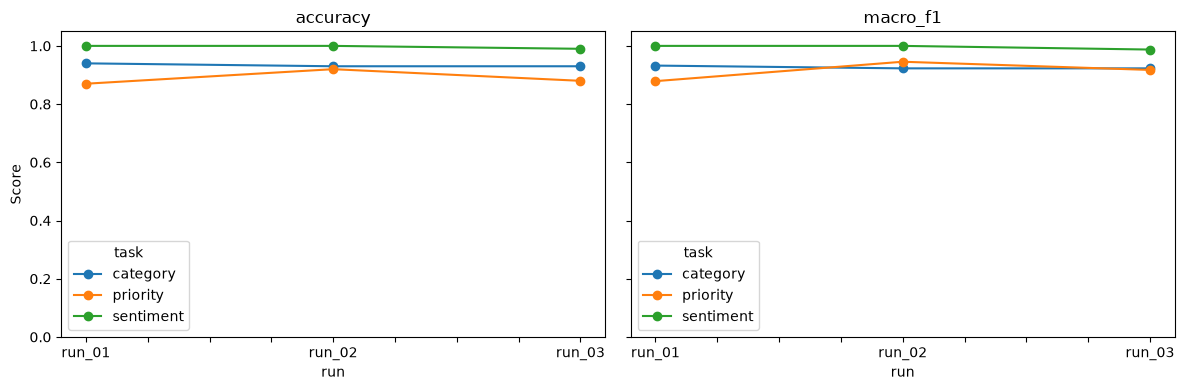

,task,all_runs_agree,changed_between_runs,agreement_rate
0,category,99,1,0.99
1,sentiment,99,1,0.99
2,priority,91,9,0.91


In [6]:
if all_metrics:
    pooled = details[details.run.isin(complete_runs)]
    if len(pooled):
        for field, labels in LABELS.items():
            matrix = confusion_matrix(
                pooled[f"expected_{field}"],
                pooled[f"predicted_{field}"],
                labels=labels,
            )
            pd.DataFrame(matrix, index=labels, columns=labels).to_csv(
                summary_dir / f"pooled_confusion_{field}.csv"
            )
            plot_matrix(
                matrix,
                labels,
                f"{field}: {len(complete_runs)} runs x "
                f"{len(tickets)} tickets ({len(pooled)} decisions)",
                summary_dir / f"pooled_confusion_{field}",
            )
        fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
        for ax, metric in zip(axes, ["accuracy", "macro_f1"]):
            comparison.pivot(index="run", columns="task", values=metric).plot(
                marker="o", ax=ax
            )
            ax.set(title=metric, ylim=(0, 1.05), ylabel="Score")
        fig.tight_layout()
        fig.savefig(summary_dir / "run_comparison.png", dpi=200)
        fig.savefig(summary_dir / "run_comparison.pdf")
        plt.show()
        plt.close(fig)

    if len(complete_runs) == N_RUNS:
        stability = []
        for field in LABELS:
            wide = pooled.pivot(
                index="id", columns="run", values=f"predicted_{field}"
            )
            consistent = wide.nunique(axis=1) == 1
            stability.append(
                {
                    "task": field,
                    "all_runs_agree": int(consistent.sum()),
                    "changed_between_runs": int((~consistent).sum()),
                    "agreement_rate": consistent.mean(),
                }
            )
            wide.assign(all_runs_agree=consistent).to_csv(
                summary_dir / f"stability_{field}_by_ticket.csv"
            )
        stability = pd.DataFrame(stability)
        stability.to_csv(summary_dir / "stability.csv", index=False)
        display(stability)
    else:
        print("Stability requires all configured runs to be fully successful.")
    print("Reports saved to:", EXPERIMENT_DIR.resolve())
else:
    print(
        "No saved runs. Configure the experiment "
        "and enable RUN_ANALYSIS to collect results."
    )

## 6. Estimated API cost

[Standard OpenAI rates](https://developers.openai.com/api/docs/pricing), checked
2026-11-11: **$0.10/M input tokens** and **$0.50/M output tokens** for `gpt-6-luna`.
Estimates use uncached rates and recorded usage; missing usage, cache adjustments,
surcharges, taxes and hosting are excluded.


In [7]:
if runtime_rows:
    cost_by_run, cost_summary = estimate_costs(
        pd.DataFrame(runtime_rows).assign(method="MCP"),
        loaded_settings[0]["model"],
    )
    display(cost_by_run.round(6), cost_summary.round(6))
    cost_by_run.to_csv(summary_dir / "cost_by_run.csv", index=False)
    cost_summary.to_csv(summary_dir / "cost_summary.csv")
else:
    print("No saved usage available for cost estimates.")

,method,run,usage_available_tickets,usage_missing_tickets,observed_input_tokens,observed_output_tokens,pricing_model,pricing_date,input_usd_per_million,output_usd_per_million,estimated_input_cost_usd,estimated_output_cost_usd,estimated_total_cost_usd,mean_ticket_cost_usd
0,MCP,run_01,100,0,906126,106107,gpt-6-luna,2026-11-11,0.1,0.5,0.090613,0.053054,0.143666,0.001437
1,MCP,run_02,100,0,904563,105322,gpt-6-luna,2026-11-11,0.1,0.5,0.090456,0.052661,0.143117,0.001431
2,MCP,run_03,100,0,899367,103553,gpt-6-luna,2026-11-11,0.1,0.5,0.089937,0.051776,0.141713,0.001417


,runs,tickets_with_usage,tickets_without_usage,estimated_total_cost_usd,mean_run_cost_usd,std_run_cost_usd,mean_ticket_cost_usd
method,,,,,,,
MCP,3,300,0,0.428497,0.142832,0.001007,0.001428
